# Lab 1 — Trois paradigmes d'apprentissage sur un même atelier

**De l'IA au LLM agentique · Séance 1 · ASTRE, ENSIM, Le Mans Université**
*Bassem Ben Hamed & Ali Khalfallah*

Ce lab se fait **en autonomie, après la séance 1**. Il valide les notions du cours :
- les **exemples numériques des slides**, recalculés en Python ;
- les **trois paradigmes**, mis en œuvre sur un même atelier instrumenté :
  - supervisé, pour prédire les pannes ;
  - non supervisé, pour détecter l'atypique sans étiquettes ;
  - par renforcement, pour apprendre à chauffer une pièce ;
- le **MLOps**, avec une carte de modèle et une dérive de capteur simulée ;
- cinq **exercices de validation**, vérifiés automatiquement, avec un corrigé en fin de notebook.

**Prérequis** : Python, NumPy et pandas de base. **Exécution** : Google Colab ou Jupyter, un CPU suffit, environ une minute.

> **Données** : *AI4I 2020 Predictive Maintenance Dataset* (S. Matzka, 2020), UCI Machine Learning Repository (id 601), licence CC BY 4.0.
> C'est un jeu **synthétique**, construit pour reproduire le comportement d'un atelier réel.

## Rappel des formules de la séance

| Notion | Formule |
|---|---|
| Risque empirique | $\hat R(f) = \frac{1}{N}\sum_i \ell(f(\mathbf{x}_i), y_i)$ |
| Règle de Bayes | $P(\text{panne}\mid\text{alarme}) = \dfrac{P(\text{alarme}\mid\text{panne})\,P(\text{panne})}{P(\text{alarme})}$ |
| Précision, rappel, F1 | $P = \frac{VP}{VP+FP}$, $R = \frac{VP}{VP+FN}$, $F_1 = \frac{2PR}{P+R}$ |
| k-moyennes | $J = \sum_k \sum_{\mathbf{x}\in C_k} \lVert \mathbf{x}-\boldsymbol\mu_k\rVert^2$ |
| Score $z$ | $z = (x-\mu)/\sigma$, alerte si $\lvert z\rvert > 3$ |
| Retour cumulé | $G_t = \sum_k \gamma^k r_{t+k+1}$ |
| Q-learning | $Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$ |
| Indice PSI | $\mathrm{PSI} = \sum_i (q_i - p_i)\ln(q_i/p_i)$ |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score)

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
SEED = 42

## Partie A — Recalculer les exemples des slides

Chaque cellule reprend un exemple numérique du cours. Vérifiez que vous retrouvez les mêmes valeurs.

In [2]:
# Risque empirique : trois mesures, deux modèles linéaires
x = np.array([1, 2, 3]); y = np.array([2, 4, 5])
for nom, y_hat in [("ŷ = 2x", 2 * x), ("ŷ = 1,5x + 0,667", 1.5 * x + 2 / 3)]:
    print(f"{nom:18s} erreurs = {np.round(y_hat - y, 3)}  →  R̂ = {np.mean((y_hat - y) ** 2):.3f}")
a, b = np.polyfit(x, y, 1)
print(f"Droite des moindres carrés : a = {a:.3f}, b = {b:.3f}")

ŷ = 2x             erreurs = [0 0 1]  →  R̂ = 0.333
ŷ = 1,5x + 0,667   erreurs = [ 0.167 -0.333  0.167]  →  R̂ = 0.056
Droite des moindres carrés : a = 1.500, b = 0.667


In [3]:
# Règle de Bayes sur une alarme de vibration
p_panne, p_alarme_si_panne, p_alarme_si_normal = 0.034, 0.9, 0.05
p_alarme = p_alarme_si_panne * p_panne + p_alarme_si_normal * (1 - p_panne)
print(f"P(alarme)         = {p_alarme:.4f}")
print(f"P(panne | alarme) = {p_alarme_si_panne * p_panne / p_alarme:.3f}")

P(alarme)         = 0.0789
P(panne | alarme) = 0.388


In [4]:
# Précision, rappel, F1 (matrice de confusion de la forêt aléatoire, partie 1)
VP, FN, FP = 64, 21, 5
P, R = VP / (VP + FP), VP / (VP + FN)
print(f"précision = {P:.3f}   rappel = {R:.3f}   F1 = {2 * P * R / (P + R):.3f}")

précision = 0.928   rappel = 0.753   F1 = 0.831


In [5]:
# Puissance mécanique, k-moyennes 1D, score z, valeur efficace
omega = 1500 * 2 * np.pi / 60
print(f"ω = {omega:.1f} rad/s   P = 40 × ω = {40 * omega:.0f} W")
pts, mu = np.array([1, 2, 9, 10]), np.array([1.5, 9.5])
print("J (k-moyennes) =", sum(min((p - m) ** 2 for m in mu) for p in pts))
print(f"z = (313,5 − 310) / 1,5 = {(313.5 - 310) / 1.5:.2f}")
print(f"RMS de (1, −1, 2, −2) = {np.sqrt(np.mean(np.array([1, -1, 2, -2]) ** 2)):.3f}")

ω = 157.1 rad/s   P = 40 × ω = 6283 W
J (k-moyennes) = 1.0
z = (313,5 − 310) / 1,5 = 2.33
RMS de (1, −1, 2, −2) = 1.581


In [6]:
# Retour cumulé, mise à jour du Q-learning, indice PSI
print(f"G = 1 + 0,9×0 + 0,9²×2 = {1 + 0.9 * 0 + 0.9 ** 2 * 2:.2f}")
print(f"Q ← 0 + 0,1 × (−0,5 + 0,95 × (−2) − 0) = {0 + 0.1 * (-0.5 + 0.95 * (-2) - 0):.2f}")
p, q = np.array([0.25, 0.50, 0.25]), np.array([0.10, 0.50, 0.40])
print("termes du PSI :", np.round((q - p) * np.log(q / p), 3), " PSI =", round(float(((q - p) * np.log(q / p)).sum()), 3))

G = 1 + 0,9×0 + 0,9²×2 = 2.62
Q ← 0 + 0,1 × (−0,5 + 0,95 × (−2) − 0) = -0.24
termes du PSI : [0.137 0.    0.071]  PSI = 0.208


## Partie B — Les données de l'atelier

### Description

Chaque ligne est un cycle d'usinage. Les cinq mesures capteurs :

- température de l'air et du process (K) ;
- vitesse de rotation (tr/min) ;
- couple (N·m) ;
- usure de l'outil (min).

Le type de produit vaut L, M ou H, selon la qualité. L'étiquette `panne` vaut 1 si la machine est tombée en panne pendant le cycle.

In [7]:
URL = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
try:
    df = pd.read_csv(URL, compression="zip")
except Exception as e:  # repli si le site UCI est indisponible
    print("Téléchargement direct impossible :", e)
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"], check=True)
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=601)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)

df.columns = [c.replace("﻿", "").strip() for c in df.columns]
df = df.rename(columns={
    "Air temperature [K]": "T_air_K",
    "Process temperature [K]": "T_process_K",
    "Rotational speed [rpm]": "vitesse_rpm",
    "Torque [Nm]": "couple_Nm",
    "Tool wear [min]": "usure_outil_min",
    "Machine failure": "panne",
})
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,T_air_K,T_process_K,vitesse_rpm,couple_Nm,usure_outil_min,panne,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [8]:
taux = df["panne"].mean()
print(f"{len(df)} cycles, {df['panne'].sum()} pannes → taux de panne = {taux:.2%}\n")
modes = {"TWF": "usure d'outil", "HDF": "dissipation thermique", "PWF": "puissance",
         "OSF": "surcontrainte", "RNF": "aléatoire"}
print("Pannes par mode (un cycle peut en cumuler plusieurs) :")
for k, v in modes.items():
    print(f"  {k} ({v:22s}) : {df[k].sum():4d}")

10000 cycles, 339 pannes → taux de panne = 3.39%

Pannes par mode (un cycle peut en cumuler plusieurs) :
  TWF (usure d'outil         ) :   46
  HDF (dissipation thermique ) :  115
  PWF (puissance             ) :   95
  OSF (surcontrainte         ) :   98
  RNF (aléatoire             ) :   19


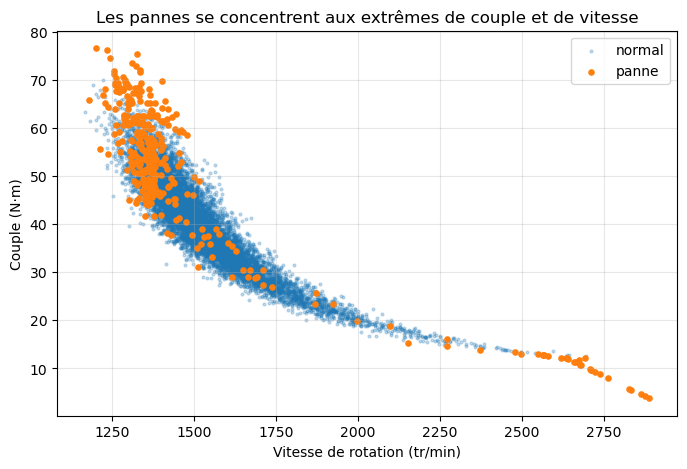

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ok, ko = df[df.panne == 0], df[df.panne == 1]
ax.scatter(ok.vitesse_rpm, ok.couple_Nm, s=4, alpha=0.25, label="normal")
ax.scatter(ko.vitesse_rpm, ko.couple_Nm, s=14, c="tab:orange", label="panne")
ax.set_xlabel("Vitesse de rotation (tr/min)"); ax.set_ylabel("Couple (N·m)")
ax.set_title("Les pannes se concentrent aux extrêmes de couple et de vitesse")
ax.legend(); plt.show()

**À noter.** Les pannes représentent environ 3,4 % des cycles : les classes sont **très déséquilibrées**.
Un modèle qui répond toujours « pas de panne » obtient environ 96,6 % d'accuracy… et ne sert à rien.

## 1. Apprentissage supervisé : prédire la panne

On apprend une fonction *f(mesures) → panne* à partir d'exemples étiquetés.

**Piège de la fuite de données.** Les colonnes `TWF`, `HDF`, etc. décrivent la panne *après coup*.
Si on les donnait au modèle, il « tricherait ». On les exclut, ainsi que les identifiants.

In [10]:
CAPTEURS = ["T_air_K", "T_process_K", "vitesse_rpm", "couple_Nm", "usure_outil_min"]

def matrice(d, colonnes):
    return pd.get_dummies(d[colonnes + ["Type"]], columns=["Type"], dtype=float)

X = matrice(df, CAPTEURS)
y = df["panne"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)

print(f"Modèle naïf « jamais de panne » : accuracy = {(y_test == 0).mean():.1%}, rappel des pannes = 0 %")

Modèle naïf « jamais de panne » : accuracy = 96.6%, rappel des pannes = 0 %


              precision    recall  f1-score   support

      normal      0.985     0.995     0.990      2415
       panne      0.790     0.576     0.667        85

    accuracy                          0.980      2500
   macro avg      0.888     0.786     0.828      2500
weighted avg      0.979     0.980     0.979      2500



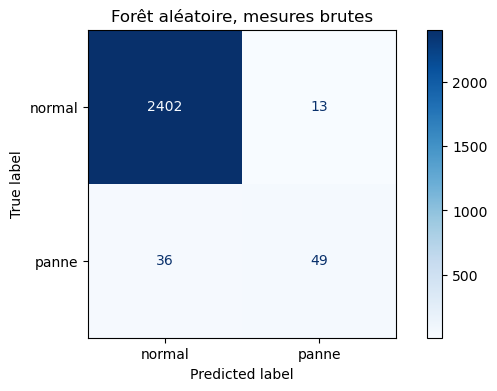

In [11]:
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced",
                            random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["normal", "panne"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["normal", "panne"], cmap="Blues")
plt.title("Forêt aléatoire, mesures brutes"); plt.grid(False); plt.show()

### Ajouter la connaissance métier

Un ingénieur sait que :

- la **puissance mécanique** vaut *P = C·ω* ;
- l'**écart de température** process − air conditionne la dissipation thermique.

On fournit ces deux grandeurs au modèle. C'est du *feature engineering*, l'équivalent des descripteurs (RMS, FFT…) que vous calculez en traitement du signal.

mesures brutes     → F1(panne) = 0.667   rappel = 0.576   précision = 0.790
+ puissance, ΔT    → F1(panne) = 0.831   rappel = 0.753   précision = 0.928


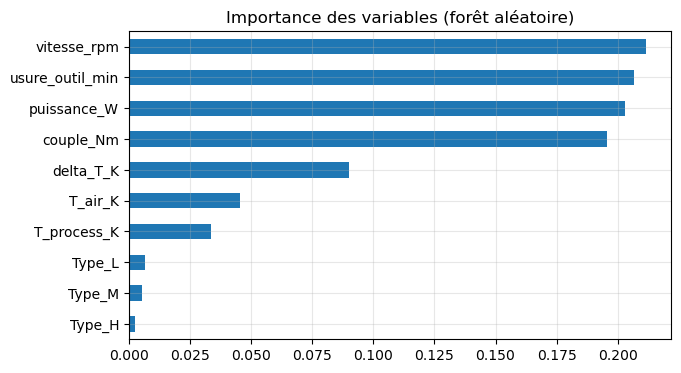

In [12]:
df["puissance_W"] = df["couple_Nm"] * df["vitesse_rpm"] * 2 * np.pi / 60
df["delta_T_K"] = df["T_process_K"] - df["T_air_K"]
CAPTEURS_PLUS = CAPTEURS + ["puissance_W", "delta_T_K"]

X2 = matrice(df, CAPTEURS_PLUS)
X2_train, X2_test = X2.loc[X_train.index], X2.loc[X_test.index]
rf2 = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced",
                             random_state=SEED, n_jobs=-1).fit(X2_train, y_train)
y_pred2 = rf2.predict(X2_test)

for nom, yp in [("mesures brutes", y_pred), ("+ puissance, ΔT", y_pred2)]:
    print(f"{nom:18s} → F1(panne) = {f1_score(y_test, yp):.3f}   "
          f"rappel = {recall_score(y_test, yp):.3f}   précision = {precision_score(y_test, yp):.3f}")

imp = pd.Series(rf2.feature_importances_, index=X2.columns).sort_values()
imp.plot.barh(figsize=(7, 4), title="Importance des variables (forêt aléatoire)"); plt.show()

## 2. Apprentissage non supervisé : sans étiquettes

En pratique, on dispose souvent de **beaucoup de données de fonctionnement normal** et de **très peu de pannes étiquetées**.
On cherche alors ce qui est **inhabituel**. Ici, on utilise une *Isolation Forest* : un point est d'autant plus suspect qu'il est facile à isoler par des coupes aléatoires.

Les étiquettes ne servent **qu'à la fin**, pour évaluer.

In [13]:
X_ns = StandardScaler().fit_transform(df[CAPTEURS_PLUS])
iso = IsolationForest(n_estimators=300, contamination=float(taux), random_state=SEED)
anomalie = (iso.fit_predict(X_ns) == -1).astype(int)

print(f"Cycles signalés anormaux : {anomalie.sum()}")
print(f"Parmi eux, vraies pannes : {precision_score(y, anomalie):.1%} (précision)")
print(f"Pannes retrouvées        : {recall_score(y, anomalie):.1%} (rappel)")

Cycles signalés anormaux : 339
Parmi eux, vraies pannes : 26.5% (précision)
Pannes retrouvées        : 26.5% (rappel)


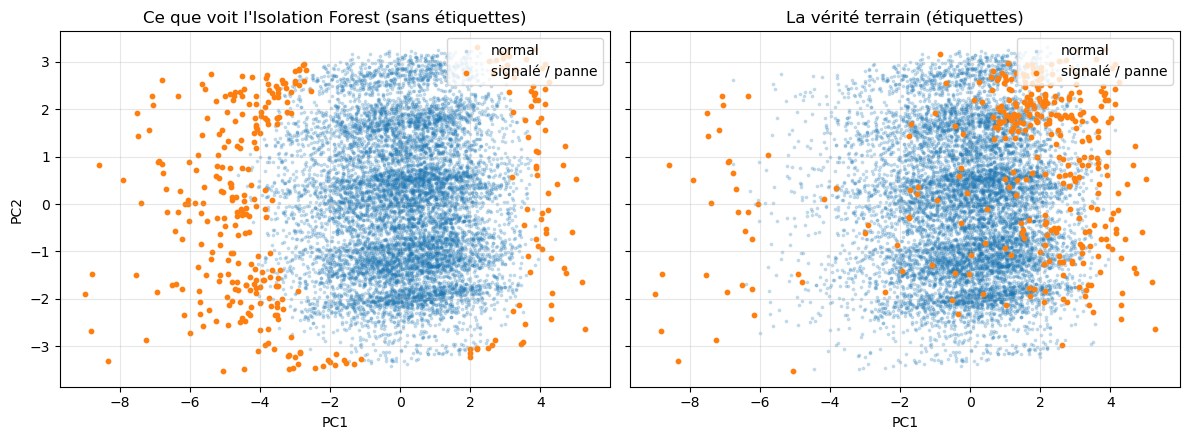

In [14]:
Z = PCA(n_components=2, random_state=SEED).fit_transform(X_ns)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, couleur, titre in [(axes[0], anomalie, "Ce que voit l'Isolation Forest (sans étiquettes)"),
                           (axes[1], y, "La vérité terrain (étiquettes)")]:
    ax.scatter(Z[couleur == 0, 0], Z[couleur == 0, 1], s=3, alpha=0.2, label="normal")
    ax.scatter(Z[couleur == 1, 0], Z[couleur == 1, 1], s=10, c="tab:orange", label="signalé / panne")
    ax.set_title(titre); ax.set_xlabel("PC1"); ax.legend(loc="upper right")
axes[0].set_ylabel("PC2"); plt.tight_layout(); plt.show()

**À retenir.** Le non supervisé détecte de l'**atypique**, pas forcément de la **panne**.
Il ne demande aucune étiquette, mais ses performances sont nettement inférieures au supervisé.
On l'utilise souvent comme **premier filtre** : il signale des cas, qu'un expert étiquette ensuite. Ces étiquettes servent à entraîner le modèle supervisé.

## 3. Apprentissage par renforcement : apprendre à chauffer

Changement de décor : un **agent** commande le chauffage d'une pièce.

- **État** : la température mesurée, discrétisée par pas de 0,5 °C.
- **Actions** : chauffe à 0 %, 50 % ou 100 %.
- **Récompense** : − |T − 21 °C| − 0,3 × puissance. On pénalise l'inconfort **et** l'énergie consommée.

Personne ne lui donne la bonne réponse. Il l'apprend **par essais et erreurs** avec le *Q-learning*.

Le modèle thermique est du premier ordre, comme en automatique : $T_{k+1} = T_k + a\,P_k - b\,(T_k - T_{ext}) + \varepsilon$.

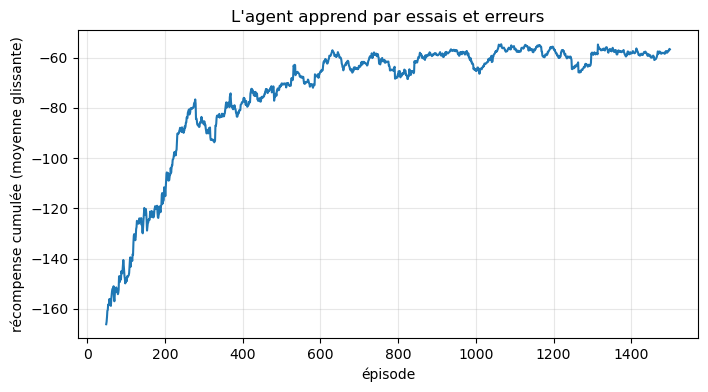

In [15]:
class Thermostat:
    ACTIONS = np.array([0.0, 0.5, 1.0])          # puissance de chauffe
    T_MIN, PAS, N_ETATS = 10.0, 0.5, 48           # états : 10 °C → 34 °C

    def __init__(self, T_cible=21.0, T_ext=8.0, a=1.2, b=0.05, seed=0):
        self.T_cible, self.T_ext, self.a, self.b = T_cible, T_ext, a, b
        self.rng = np.random.default_rng(seed)

    def etat(self):
        return int(np.clip((self.T - self.T_MIN) / self.PAS, 0, self.N_ETATS - 1))

    def reset(self):
        self.T = self.rng.uniform(12, 30)
        return self.etat()

    def step(self, action):
        P = self.ACTIONS[action]
        self.T += self.a * P - self.b * (self.T - self.T_ext) + self.rng.normal(0, 0.2)
        recompense = -abs(self.T - self.T_cible) - 0.3 * P
        return self.etat(), recompense, P


env = Thermostat(seed=SEED)
rng = np.random.default_rng(SEED)
Q = np.zeros((env.N_ETATS, len(env.ACTIONS)))
alpha, gamma, eps = 0.1, 0.95, 1.0
historique = []

for episode in range(1500):
    s, total = env.reset(), 0.0
    for t in range(100):
        a = rng.integers(3) if rng.random() < eps else int(Q[s].argmax())   # exploration / exploitation
        s2, r, _ = env.step(a)
        Q[s, a] += alpha * (r + gamma * Q[s2].max() - Q[s, a])             # mise à jour de Bellman
        s, total = s2, total + r
    eps = max(0.02, eps * 0.996)
    historique.append(total)

plt.plot(pd.Series(historique).rolling(50).mean())
plt.xlabel("épisode"); plt.ylabel("récompense cumulée (moyenne glissante)")
plt.title("L'agent apprend par essais et erreurs"); plt.show()

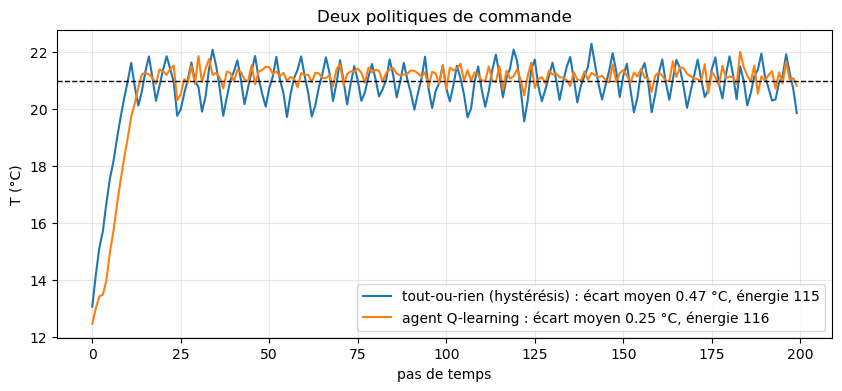

Politique apprise (puissance choisie selon la température) :
  17.0 °C → 100 %
  17.5 °C → 100 %
  18.0 °C → 100 %
  18.5 °C → 100 %
  19.0 °C → 100 %
  19.5 °C → 100 %
  20.0 °C → 100 %
  20.5 °C → 100 %
  21.0 °C →  50 %
  21.5 °C →   0 %
  22.0 °C →   0 %
  22.5 °C →   0 %
  23.0 °C →   0 %
  23.5 °C →   0 %
  24.0 °C →   0 %
  24.5 °C →   0 %


In [16]:
def simuler(politique, n=200, T0=12.0, seed=1):
    e = Thermostat(seed=seed); e.T = T0
    Ts, Ps = [], []
    for _ in range(n):
        _, _, P = e.step(politique(e))
        Ts.append(e.T); Ps.append(P)
    return np.array(Ts), np.array(Ps)

agent_rl = lambda e: int(Q[e.etat()].argmax())

def tout_ou_rien(e, etat={"on": True}):          # thermostat à hystérésis classique
    if e.T < 20.5: etat["on"] = True
    elif e.T > 21.5: etat["on"] = False
    return 2 if etat["on"] else 0

fig, ax = plt.subplots(figsize=(10, 4))
for nom, pol in [("tout-ou-rien (hystérésis)", tout_ou_rien), ("agent Q-learning", agent_rl)]:
    Ts, Ps = simuler(pol)
    ax.plot(Ts, label=f"{nom} : écart moyen {np.abs(Ts[50:] - 21).mean():.2f} °C, énergie {Ps.sum():.0f}")
ax.axhline(21, ls="--", c="k", lw=1); ax.set_xlabel("pas de temps"); ax.set_ylabel("T (°C)")
ax.legend(); ax.set_title("Deux politiques de commande"); plt.show()

T_axe = env.T_MIN + env.PAS * np.arange(env.N_ETATS)
print("Politique apprise (puissance choisie selon la température) :")
for T, a in zip(T_axe[14:30], Q[14:30].argmax(1)):
    print(f"  {T:4.1f} °C → {int(100 * env.ACTIONS[a]):3d} %")

L'agent a **découvert seul** une loi de commande proche de ce qu'un automaticien aurait conçu :

- il chauffe fort quand la température est basse ;
- il module autour de la consigne ;
- il coupe quand la température est trop haute.

Il a aussi intégré le coût énergétique, qu'on lui a fixé dans la récompense.

## 4. Vers le MLOps : le modèle en production

Un modèle entraîné n'est qu'un **artefact**. Il faut le versionner, documenter ses performances et **surveiller** son comportement une fois déployé.

In [17]:
import json, datetime, os, tempfile, joblib, sklearn
SORTIES = tempfile.mkdtemp(prefix="lab1_")   # dossier temporaire : rien n'est écrit à côté du notebook
joblib.dump(rf2, f"{SORTIES}/modele_panne_rf.joblib")
carte = {
    "modele": "RandomForestClassifier", "version": "0.1.0",
    "date": datetime.date.today().isoformat(),
    "donnees": "AI4I 2020 (UCI id 601)", "variables": list(X2.columns),
    "metriques_test": {"f1_panne": round(f1_score(y_test, y_pred2), 3),
                       "rappel_panne": round(recall_score(y_test, y_pred2), 3)},
    "scikit_learn": sklearn.__version__,
}
with open(f"{SORTIES}/carte_modele.json", "w", encoding="utf-8") as f:
    json.dump(carte, f, indent=2, ensure_ascii=False)
print(json.dumps(carte, indent=2, ensure_ascii=False))
print(f"Taille du modèle : {os.path.getsize(f'{SORTIES}/modele_panne_rf.joblib') / 1e6:.1f} Mo   (STM32F446 : 512 Ko de Flash)")

{
  "modele": "RandomForestClassifier",
  "version": "0.1.0",
  "date": "2026-11-23",
  "donnees": "AI4I 2020 (UCI id 601)",
  "variables": [
    "T_air_K",
    "T_process_K",
    "vitesse_rpm",
    "couple_Nm",
    "usure_outil_min",
    "puissance_W",
    "delta_T_K",
    "Type_H",
    "Type_L",
    "Type_M"
  ],
  "metriques_test": {
    "f1_panne": 0.831,
    "rappel_panne": 0.753
  },
  "scikit_learn": "1.7.2"
}
Taille du modèle : 3.9 Mo   (STM32F446 : 512 Ko de Flash)


### Simulation d'une dérive : on remplace le capteur de température process

Six mois après le déploiement, la maintenance remplace la sonde de température process. La nouvelle sonde mesure **+2 K de trop** (offset).
Aucune alerte ne se déclenche : le modèle continue de répondre… mais ses réponses sont-elles encore bonnes ?

In [18]:
X_derive = X2_test.copy()
X_derive["T_process_K"] += 2.0
X_derive["delta_T_K"] += 2.0
y_pred_derive = rf2.predict(X_derive)

hdf_test = df.loc[X_test.index, "HDF"].values == 1
for nom, yp in [("capteur d'origine", y_pred2), ("capteur décalé +2 K", y_pred_derive)]:
    print(f"{nom:20s} → rappel global = {recall_score(y_test, yp):.1%}   "
          f"pannes thermiques (HDF) détectées = {yp[hdf_test].mean():.1%}")

capteur d'origine    → rappel global = 75.3%   pannes thermiques (HDF) détectées = 94.4%
capteur décalé +2 K  → rappel global = 37.6%   pannes thermiques (HDF) détectées = 2.8%


Le modèle **rate des pannes thermiques** sans que rien ne le signale : c'est une **dérive des données** (*data drift*).
Le MLOps sert à la détecter, en surveillant les distributions d'entrée et les performances, puis à déclencher un ré-entraînement.

### Synthèse

| Paradigme | Ce qu'on fournit | Ce qu'on obtient | Ici |
|---|---|---|---|
| Supervisé | des exemples **étiquetés** | un prédicteur | forêt aléatoire, F1 ≈ 0,83 avec les variables métier |
| Non supervisé | des données **sans** étiquettes | des structures, de l'atypique | Isolation Forest, environ 26 % des pannes retrouvées |
| Renforcement | un environnement et une **récompense** | une politique d'action | thermostat Q-learning |

## Partie C — Exercices de validation

Complétez chaque fonction : remplacez `return None` par votre calcul.
Le vérificateur affiche **« À compléter »**, **« Correct »** ou **« Incorrect »**. Le corrigé figure à la fin du notebook.

In [19]:
def verifier(nom, valeur, attendu, tol=1e-3):
    if valeur is None:
        print(f"{nom} : À compléter")
    elif abs(float(valeur) - attendu) <= tol:
        print(f"{nom} : Correct ({float(valeur):.4g})")
    else:
        print(f"{nom} : Incorrect (obtenu {float(valeur):.4g}, attendu {attendu:.4g})")

def verifier_tout():
    verifier("Exercice 1 — Bayes", proba_panne_sachant_alarme(0.034, 0.9, 0.05), 0.388)
    verifier("Exercice 2 — F1", f1(64, 5, 21), 0.831)
    verifier("Exercice 3 — retour cumulé", retour([1, 0, 2], 0.9), 2.62)
    verifier("Exercice 4 — Q-learning", maj_q(0.0, -0.5, 0.95, -2.0, 0.1), -0.24)
    verifier("Exercice 5 — PSI", psi([0.25, 0.5, 0.25], [0.10, 0.5, 0.40]), 0.208)

**Exercice 1 — Règle de Bayes.** Écrivez la probabilité qu'une alarme corresponde à une vraie panne.

Puis, en dehors du vérificateur : que devient-elle si le taux de panne passe de 3,4 % à 10 % ?

In [20]:
def proba_panne_sachant_alarme(p_panne, p_alarme_si_panne, p_alarme_si_normal):
    # À compléter
    return None

**Exercice 2 — F1.** Calculez le score F1 à partir de VP, FP et FN.

In [21]:
def f1(vp, fp, fn):
    # À compléter
    return None

**Exercice 3 — Retour cumulé.** Calculez $G = \sum_k \gamma^k r_{k+1}$ pour une liste de récompenses.

In [22]:
def retour(recompenses, gamma):
    # À compléter
    return None

**Exercice 4 — Q-learning.** Écrivez une mise à jour de Q-learning, qui renvoie la nouvelle valeur de $Q(s,a)$.

Pour aller plus loin, relancez la partie 3 avec une pénalité énergétique de 1,0 au lieu de 0,3. Comment évolue la politique apprise ?

In [23]:
def maj_q(q, r, gamma, max_q_suivant, alpha):
    # À compléter
    return None

**Exercice 5 — PSI.** Calculez l'indice PSI entre deux distributions $p$ (entraînement) et $q$ (production).

Pour aller plus loin :
1. Découpez `T_process_K` du jeu de test en 5 classes, avec les quantiles de l'entraînement.
2. Calculez le PSI entre le capteur d'origine et le capteur décalé de +2 K.
3. Ce PSI aurait-il déclenché une alerte ?

In [24]:
def psi(p, q):
    # À compléter
    return None

In [25]:
verifier_tout()

Exercice 1 — Bayes : À compléter
Exercice 2 — F1 : À compléter
Exercice 3 — retour cumulé : À compléter
Exercice 4 — Q-learning : À compléter
Exercice 5 — PSI : À compléter


## Corrigé

À consulter **après** avoir cherché. On redéfinit les cinq fonctions, puis on relance les vérifications.

In [26]:
def proba_panne_sachant_alarme(p_panne, p_alarme_si_panne, p_alarme_si_normal):
    p_alarme = p_alarme_si_panne * p_panne + p_alarme_si_normal * (1 - p_panne)
    return p_alarme_si_panne * p_panne / p_alarme

def f1(vp, fp, fn):
    p, r = vp / (vp + fp), vp / (vp + fn)
    return 2 * p * r / (p + r)

def retour(recompenses, gamma):
    return sum(gamma ** k * r for k, r in enumerate(recompenses))

def maj_q(q, r, gamma, max_q_suivant, alpha):
    return q + alpha * (r + gamma * max_q_suivant - q)

def psi(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    return float(np.sum((q - p) * np.log(q / p)))

verifier_tout()
print(f"\nBayes avec 10 % de pannes : {proba_panne_sachant_alarme(0.10, 0.9, 0.05):.3f}")

Exercice 1 — Bayes : Correct (0.3878)
Exercice 2 — F1 : Correct (0.8312)
Exercice 3 — retour cumulé : Correct (2.62)
Exercice 4 — Q-learning : Correct (-0.24)
Exercice 5 — PSI : Correct (0.2079)

Bayes avec 10 % de pannes : 0.667


In [27]:
# Pour aller plus loin (exercice 5) : PSI du capteur décalé
bornes = np.quantile(X2_train["T_process_K"], [0.2, 0.4, 0.6, 0.8])
def parts(v):
    return np.bincount(np.digitize(v, bornes), minlength=5) / len(v)
p_ref = parts(X2_train["T_process_K"])
for nom, v in [("capteur d'origine", X2_test["T_process_K"]), ("capteur décalé +2 K", X_derive["T_process_K"])]:
    q_v = np.clip(parts(v), 1e-4, None)
    print(f"{nom:20s} PSI = {psi(p_ref, q_v):.3f}")

capteur d'origine    PSI = 0.001
capteur décalé +2 K  PSI = 1.463


Le PSI du capteur décalé dépasse largement 0,25 : une surveillance des entrées aurait **alerté**, alors que le modèle, lui, ne signalait rien.

**Prochaine séance** : on ouvre la boîte, du neurone formel au perceptron multicouche (lab 2).